**Cell 1 — Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

**Cell 2 — Read the CSV files**

(Make sure the filenames match exactly.)

In [ ]:
fake = pd.read_csv("/content/Fake.csv")
real = pd.read_csv("/content/True.csv")

print("Fake articles:", len(fake))
print("Real articles:", len(real))

fake.head()

Fake articles: 23481
Real articles: 21417


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


**Cell 3 — Add labels and combine**

(We use 0 = Fake and 1 = Real.)

In [ ]:
fake["label"] = 0
real["label"] = 1

df = pd.concat([fake, real], ignore_index=True)

# Use only article text and its label.
df = df[["text", "label"]].copy()

print("Total articles:", len(df))
df.head()

Total articles: 44898


,text,label
0,Donald Trump just couldn t wish all Americans ...,0
1,House Intelligence Committee Chairman Devin Nu...,0
2,"On Friday, it was revealed that former Milwauk...",0
3,"On Christmas day, Donald Trump announced that ...",0
4,Pope Francis used his annual Christmas Day mes...,0


**Cell 4 — Remove missing or empty articles**

In [ ]:
df["text"] = df["text"].fillna("").astype(str)

# Create normalized keys for finding empty and repeated articles.
df["key"] = (
    df["text"]
    .str.lower()
    .str.replace(r"[\W_]+", " ", regex=True)
    .str.strip()
)

before = len(df)

df = df[
    df["key"].str.contains(r"[a-z]{2,}", regex=True)
].copy()

print("Empty or unusable articles removed:", before - len(df))

Empty or unusable articles removed: 631


**Cell 5 — Remove conflicting labels and duplicates**

(This prevents copies of the same article from appearing in both training and testing.)

In [ ]:
before = len(df)

# Remove articles whose identical normalized text has both labels.
label_counts = df.groupby("key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index

df = df[~df["key"].isin(conflicting_keys)]

# Keep one copy of each article.
df = df.drop_duplicates("key").reset_index(drop=True)

print("Conflicting or duplicate articles removed:", before - len(df))
print("Remaining articles:", len(df))

Conflicting or duplicate articles removed: 5899
Remaining articles: 38368


**Cell 6 — Check the class counts**

In [ ]:
print(df["label"].map({0: "Fake", 1: "Real"}).value_counts())

label
Real    20923
Fake    17445
Name: count, dtype: int64


**Cell 7 — Split into training and testing sets**

(Use 80% for training and 20% for testing. stratify preserves approximately the same class proportions in both sets.)

In [ ]:
train, test = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"],
)

X_train = train["text"]
y_train = train["label"]

X_test = test["text"]
y_test = test["label"]

# Verify that normalized article bodies do not overlap.
assert set(train["key"]).isdisjoint(test["key"])

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

Training articles: 30694
Testing articles: 7674


**Cell 8 — Create the model**

The pipeline combines:
- TF-IDF: converts article text into numerical features.
- Linear SVM: learns to classify those features.
Keeping them together makes saving and website integration simpler. No separate stemming, lemmatization, or custom preprocessing function is needed.

(The token pattern excludes the word “Reuters” to reduce one obvious publisher shortcut. Other source cues can still remain.)

In [ ]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        max_features=100_000,
        sublinear_tf=True,
        token_pattern=r"(?u)\b(?!reuters\b)\w\w+\b",
        dtype=np.float32,
    )),
    ("svm", LinearSVC(
        C=1.0,
        dual="auto",
        max_iter=10_000,
        random_state=42,
    )),
])

**Cell 9 — Train the model**

TF-IDF learns its vocabulary only from the training articles.

In [ ]:
model.fit(X_train, y_train)

print("Training complete.")

Training complete.


**Cell 10 — Predict the test articles**

In [ ]:
y_pred = model.predict(X_test)

print("Test predictions complete.")

Test predictions complete.


**Cell 11 — Check accuracy and classification results**

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")
print("90% target:", "MET" if accuracy >= 0.90 else "NOT MET")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    zero_division=0,
))

Test accuracy: 99.01%
90% target: MET
              precision    recall  f1-score   support

        Fake       0.99      0.98      0.99      3489
        Real       0.99      1.00      0.99      4185

    accuracy                           0.99      7674
   macro avg       0.99      0.99      0.99      7674
weighted avg       0.99      0.99      0.99      7674



**Cell 12 — Show the confusion matrix**

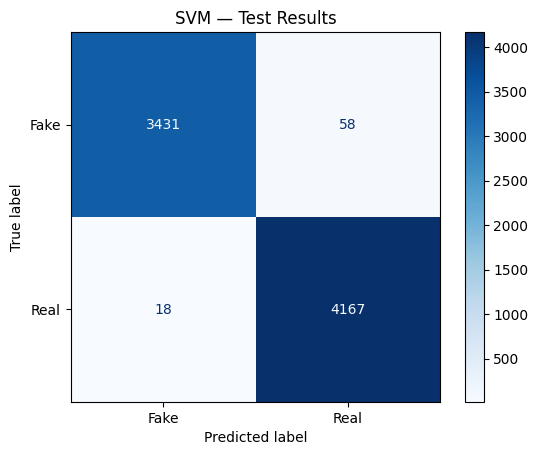

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Fake", "Real"],
    cmap="Blues",
)

plt.title("SVM — Test Results")
plt.show()

**Cell 13 — Save the complete model**

In [ ]:
model_path = "/content/fake_news_svm.joblib"

joblib.dump(model, model_path, compress=3)

print("Saved:", model_path)

Saved: /content/fake_news_svm.joblib


**Cell 14 — Verify the saved model**

In [ ]:
loaded_model = joblib.load(model_path)

loaded_predictions = loaded_model.predict(X_test)

assert np.array_equal(y_pred, loaded_predictions)

print("Verified: the saved model produces identical predictions.")

Verified: the saved model produces identical predictions.


**Cell 15 — Save results and dependency versions**

In [ ]:
import json
import platform
import sklearn
import scipy

report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    output_dict=True,
    zero_division=0,
)

results = {
    "test_accuracy": float(accuracy),
    "training_articles": len(X_train),
    "testing_articles": len(X_test),
    "labels": {"0": "Fake", "1": "Real"},
    "input": "Full English article body",
    "python_version": platform.python_version(),
    "classification_report": report,
}

with open("/content/metrics.json", "w") as file:
    json.dump(results, file, indent=2)

requirements = (
    f"scikit-learn=={sklearn.__version__}\n"
    f"numpy=={np.__version__}\n"
    f"scipy=={scipy.__version__}\n"
    f"joblib=={joblib.__version__}\n"
)

with open("/content/requirements.txt", "w") as file:
    file.write(requirements)

print("Saved metrics.json and requirements.txt")

Saved metrics.json and requirements.txt


**Cell 16 — Download your files**

In [ ]:
from google.colab import files

files.download("/content/fake_news_svm.joblib")
files.download("/content/metrics.json")
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Model Evaluation**


The fake news detection model was evaluated using an 80% training and 20% testing split. After removing empty articles, duplicate articles, and articles with conflicting labels, 30,694 articles were used for training and 7,674 articles were used for testing. The testing articles were kept separate during training to measure how well the model classified unseen examples.

The TF-IDF and Linear SVM model achieved a test accuracy of 99.01%, exceeding the project’s target of 90%. This means the model correctly classified 7,598 out of 7,674 test articles, with 76 incorrect predictions. TF-IDF learned its vocabulary only from the training articles, which prevented information from the test set from influencing the learned features.

The classification report showed strong performance for both classes. For fake news, the model achieved 99.48% precision and 98.34% recall. This means that articles predicted as fake were usually correctly classified, and the model detected most fake articles. For real news, it achieved 98.63% precision and 99.57% recall, showing that most real articles were correctly recognized. The F1-scores were approximately 98.90% for fake news and 99.10% for real news, indicating a good balance between precision and recall.

The confusion matrix provides a clearer view of the mistakes. The model incorrectly classified 58 fake articles as real and 18 real articles as fake. Therefore, it was slightly more likely to miss a fake article than to incorrectly label a real article as fake.

These results show that the model performed well on the selected dataset. However, 99.01% test accuracy does not guarantee the same performance on current news or articles from different sources. Related stories, publisher characteristics, and writing styles may make the dataset easier to classify. The system recognizes patterns associated with the dataset’s labels; it does not independently verify facts. Further evaluation using a separate dataset from different sources or time periods would help assess its practical reliability.